# ST2195 Coursework
### Author: Lacsado Shaniah Santiago
### S/N: 240726184 

## Setting Up Environment

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import os
import glob
import statsmodels.formula.api as smf

## 1. Random Walk Metropolis

### Probability Density Function

In [10]:
def f(x):
    return 0.5*np.exp(-np.abs(x))

### Metropolis-Hastings Function
First create an empty numeric array of the size N+1, which includes x0.
Then, initialize the first index with initial value.
Create a loop to generate x* from the normal distribution with mean x and standard deviation s, and a random number u from uniform distribution between 0 and 1.
Then, set x[i] if u < r, else x[i] = x[i-1]. (Note: Corrected the typo from the original R script where `<` was used instead of assignment).

In [30]:
def metropolis_hasting(N, s, x0):
    x = np.zeros(N + 1)
    x[0] = x0
    
    for i in range(1, N + 1):
        xStar = np.random.normal(loc=x[i-1], scale=s)
        
        # Formula: log(r) = log(f(x*)) - log(f(x[i-1]))
        logr = np.log(f(xStar)) - np.log(f(x[i-1]))
        
        u = np.random.uniform(0, 1)
        
        if np.log(u) < logr:
            x[i] = xStar
        else:
            x[i] = x[i-1]
            
    return x

### Setting Up Parameters
Initializing variables such as N is the number of iterations, s is the standard deviation, and x0 is the initial value.

In [16]:
N = 10000
s = 1
x0 = 0

### (a) Run Random Walk Metropolis Algorithm

In [32]:
samples = metropolis_hasting(N, s, x0)

print(f"Mean: {np.mean(samples)}")
print(f"S.D.: {np.std(samples, ddof=1)}")

Mean: -0.03975002008519638
S.D.: 1.4227915445943644


### (a) Histogram and Kernel Density Plot (KDE)
First, transform the samples into data frames for seaborn/matplotlib to be able to read.
Creating a histogram with blue bars, KDE with orange line, and an overlay of graph of f(x) with a black line. With readable titles and labels of the graphs.

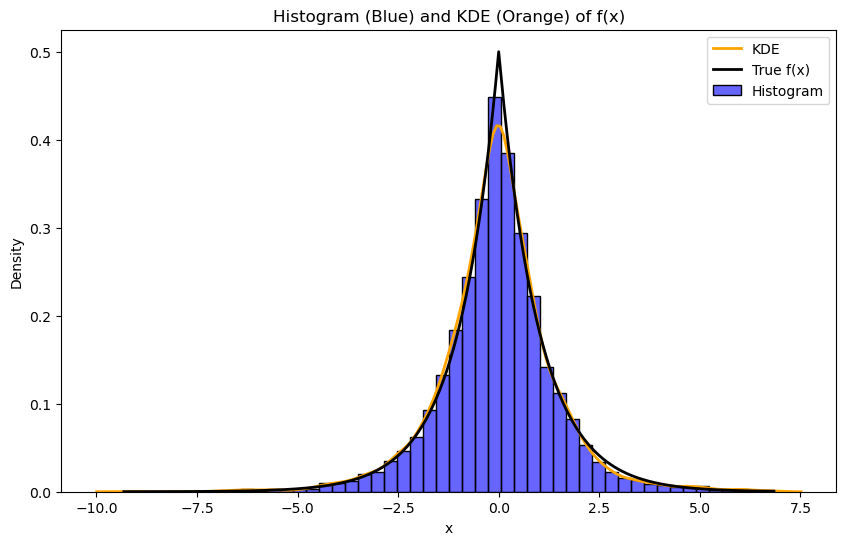

In [36]:
samplesDF = pd.DataFrame({'samples': samples})

plt.figure(figsize=(10, 6))

# Histogram and KDE
sns.histplot(samplesDF['samples'], stat='density', color='blue', alpha=0.6, label='Histogram', bins=50)
sns.kdeplot(samplesDF['samples'], color='orange', label='KDE', linewidth=2)

# Stat function f(x) overlay
x_grid = np.linspace(samples.min(), samples.max(), 1000)
y_true = f(x_grid)
plt.plot(x_grid, y_true, color='black', label='True f(x)', linewidth=2)

plt.title("Histogram (Blue) and KDE (Orange) of f(x)")
plt.xlabel("x")
plt.ylabel("Density")
plt.legend()
plt.show()

### (a) Report

In [39]:
sample_mean = np.mean(samples)
sample_sd = np.std(samples, ddof=1)

print(f"Monte Carlo Estimates based on N = {N} samples:")
print("-" * 50)
print(f"Sample Mean              : {round(sample_mean, 5)}")
print(f"Sample Standard Deviation: {round(sample_sd, 5)}")

Monte Carlo Estimates based on N = 10000 samples:
--------------------------------------------------
Sample Mean              : -0.03975
Sample Standard Deviation: 1.42279


### R Hat Function
First, generate the dispersed initial values for J chains.
Second, initialize arrays to store the mJ, mean and vJ, variance of each chain.
Creating an iteration to calculate the sample mean and variance of all j.
Then, compute overall variance, w, sample mean, m, and between sample variance, b.
Lastly, compute r hat value.

In [42]:
def r_hat_cal(N, s, J):
    x0_arr = np.random.normal(loc=0, scale=s, size=J)
    
    mJ = np.zeros(J)
    vJ = np.zeros(J)
    
    for j in range(J):
        chain_j = metropolis_hasting(N, s, x0_arr[j])
        
        # Calculate sample mean and biased variance exactly as in the R script
        mJ[j] = np.mean(chain_j)
        vJ[j] = np.mean((chain_j - mJ[j])**2)
        
    W = np.mean(vJ)
    M = np.mean(mJ)
    
    B = np.mean((mJ - M)**2)
    r_hat_val = np.sqrt((B + W) / W)
    
    return r_hat_val

### Setting Up Parameters for R Hat

In [45]:
N_r = 2000
s_r = 0.001
J = 4

### (b) Calculate R Hat for Random Walk Metropolis Algorithm

In [50]:
r_hat_value = r_hat_cal(N_r, s_r, J)
print(f"R Hat: {r_hat_value}")

R Hat: 1.4827079490836714


### Generate s values

In [55]:
s_grid = np.linspace(0.001, 1, 50)
r_hat_values = np.zeros(len(s_grid))

for k in range(len(s_grid)):
    r_hat_values[k] = r_hat_cal(N_r, s_grid[k], J)

### (b) Plot
Creating a line plot of R Hat(blue) and a threshold indicator(red-dotted).

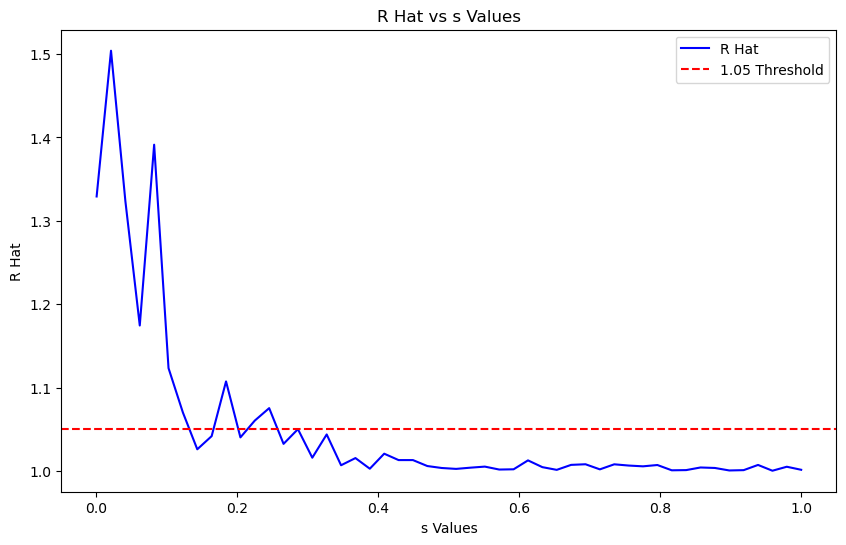

In [58]:
plot_df = pd.DataFrame({
    'StepSize': s_grid,
    'rHat': r_hat_values
})

plt.figure(figsize=(10, 6))
plt.plot(plot_df['StepSize'], plot_df['rHat'], color="blue", linewidth=1.5, label="R Hat")
plt.axhline(y=1.05, color="red", linestyle="--", linewidth=1.5, label="1.05 Threshold")

plt.title("R Hat vs s Values")
plt.xlabel("s Values")
plt.ylabel("R Hat")
plt.legend()
plt.show()

## 2. 2009 ASA Statistical Computing and Graphics Data Expo Analysis

### Create Airline Database
Create airline.db database and establish a connection to be able to execute the code.

#### Remove Existing Database (Use Only at Start)

In [65]:
if os.path.exists("airline.db"):
    os.remove("airline.db")

#### Create and Set Connection to Database
Establishing a connection with airlinedb database.

In [68]:
conn = sqlite3.connect("airline.db")

#### Initialize Database Information
Upload Airport, Carrier, Plane and OnTime(2004-2008) data from Dataverse folder to airline database.

##### Create Tables Except OnTime Table
Read Airport, Carrier and Plane CSV files in Dataverse folder in the same working directory and initialize into respective dataframe variables.

In [71]:
airport = pd.read_csv("Dataverse/airports.csv")
carrier = pd.read_csv("Dataverse/carriers.csv")
plane = pd.read_csv("Dataverse/plane-data.csv")

##### Initializing Tables to Database Except OnTime Table
Create and Write Airport, Carrier, and Plane data to airline database.

In [78]:
airport.to_sql("Airport", conn, if_exists="replace", index=False)
carrier.to_sql("Carrier", conn, if_exists="replace", index=False)
plane.to_sql("Plane", conn, if_exists="replace", index=False)

5029

##### Initialize OnTime Table
For 2004-2008 CSV files, it is stored in ontime folder in Dataverse folder.
Access the ontime folder and read the csv files and upload onTime data into airline database.

##### Get List of Files in Folder
Set directory path of ontime folder and retrieve names in the folder.

In [86]:
ontime_folder = "Dataverse/ontime/*.csv"
ontime_csvs = glob.glob(ontime_folder)

print(ontime_csvs)

['Dataverse/ontime\\2004.csv', 'Dataverse/ontime\\2005.csv', 'Dataverse/ontime\\2006.csv', 'Dataverse/ontime\\2007.csv', 'Dataverse/ontime\\2008.csv']


##### Initialize OnTime Table and Upload OnTime Table in Database
Read 2004-2008 CSV files in ontime folder into program as dataframe.
Create OnTime Table in airline database using first CSV file.
Then, the following CSV files data are appended to the OnTime Table in airline database.

In [91]:
for i, file_path in enumerate(ontime_csvs):
    ontime = pd.read_csv(file_path, encoding='ISO-8859-1') # Handles potential encoding issues in massive datasets
    if i == 0:
        ontime.to_sql("OnTime", conn, if_exists="replace", index=False)
    else:
        ontime.to_sql("OnTime", conn, if_exists="append", index=False)

##### Check Database Table Exists

In [93]:
def db_read_table_head(table_name):
    return pd.read_sql_query(f"SELECT * FROM {table_name} LIMIT 5", conn)

print(db_read_table_head("Airport"))
print(db_read_table_head("Carrier"))
print(db_read_table_head("Plane"))
print(db_read_table_head("OnTime"))

  iata               airport              city state country        lat  \
0  00M              Thigpen        Bay Springs    MS     USA  31.953765   
1  00R  Livingston Municipal        Livingston    TX     USA  30.685861   
2  00V           Meadow Lake  Colorado Springs    CO     USA  38.945749   
3  01G          Perry-Warsaw             Perry    NY     USA  42.741347   
4  01J      Hilliard Airpark          Hilliard    FL     USA  30.688012   

         long  
0  -89.234505  
1  -95.017928  
2 -104.569893  
3  -78.052081  
4  -81.905944  
  Code                    Description
0  02Q                  Titan Airways
1  04Q             Tradewind Aviation
2  05Q            Comlux Aviation, AG
3  06Q  Master Top Linhas Aereas Ltd.
4  07Q            Flair Airlines Ltd.
  tailnum  type manufacturer issue_date model status aircraft_type  \
0  N050AA  None         None       None  None   None          None   
1  N051AA  None         None       None  None   None          None   
2  N052AA  None

### (a) What are the best times and days of the week to minimise delays each year ?
Create a query that shows the Year, DayOfWeek, Hour, and MeanDelay from the OnTime Table,
Hour is calculated by CRSDepTime/100 and returned as an integer,
MeanDelay is calculated by Average of ArrDelay,
filtering ArrDelay with value and the Hour is between 0 and 23,
lastly, grouped by year, DayOfWeek, Hour.

In [96]:
part_a = """
SELECT 
    Year, 
    DayOfWeek, 
    CAST(CRSDepTime / 100 AS INTEGER) AS Hour, 
    AVG(ArrDelay) AS MeanDelay 
FROM OnTime 
WHERE ArrDelay IS NOT NULL 
  AND CAST(CRSDepTime / 100 AS INTEGER) BETWEEN 0 AND 23 
GROUP BY Year, DayOfWeek, Hour
"""

best_times = pd.read_sql_query(part_a, conn)

#### Function for Plotting Year Graph
A function that takes ontime data and creates multiple line graphs to visualise the average delays, handling 5 years of data to be displayed in a 2x2 grid.

First, define the function and parameters needed, df.
Second, create a local variable list of the years.
Third, initialise plot containing 2x2 grid of subplot.
Foruth, flatten for easier iteration as it is a 1D list.
Fifth, generate a list of 7 distinct colors to match with the dayys of the week
Sixth, create a simple text list of the days to be used for the graph legend

Then, iterate the years to display each graph into specific subplot. Filtering the each frame base on the year, and another loop to create the lines of each graph base on the day of the week.
Lastly, adding labels for identification of the line graph plot.

In [127]:
def best_times_graph(df):
    years = [2004, 2005, 2006, 2007, 2008]
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.flatten()
    
    # Custom color palette matching rainbow(7)
    colors = plt.cm.rainbow(np.linspace(0, 1, 7))
    days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
    
    for i, y in enumerate(years):
        if i > 3: # Handle the 5th year separately to avoid index out of bounds on a 2x2 grid
            break 
            
        ax = axes[i]
        df_year = df[df['Year'] == y]
        
        for day_num in range(1, 8):
            df_day = df_year[df_year['DayOfWeek'] == day_num]
            # Plot line for each day
            ax.plot(df_day['Hour'], df_day['MeanDelay'], color=colors[day_num-1], label=days[day_num-1], linewidth=1)
            
        ax.set_title(f"Year {y}")
        ax.set_xlabel("Hour")
        ax.set_ylabel("Average Delay (Min)")
        
        # Only add legend to the first plot to avoid clutter
        if i == 0:
            ax.legend(title="Day of Week", fontsize='small')

    plt.tight_layout()
    plt.show()
    
    # Plot 2008 in a separate figure (since a 2x2 grid only holds 4 graphs)
    plt.figure(figsize=(6, 4))
    df_2008 = df[df['Year'] == 2008]
    for day_num in range(1, 8):
        df_day = df_2008[df_2008['DayOfWeek'] == day_num]
        plt.plot(df_day['Hour'], df_day['MeanDelay'], color=colors[day_num-1], label=days[day_num-1], linewidth=1)
    plt.title("Year 2008")
    plt.xlabel("Hour")
    plt.ylabel("Average Delay (Min)")
    plt.show()

#### Yearly Graphs
This shows a multi-line graph of every year, showcasing the average delay base on the hour (0-23).

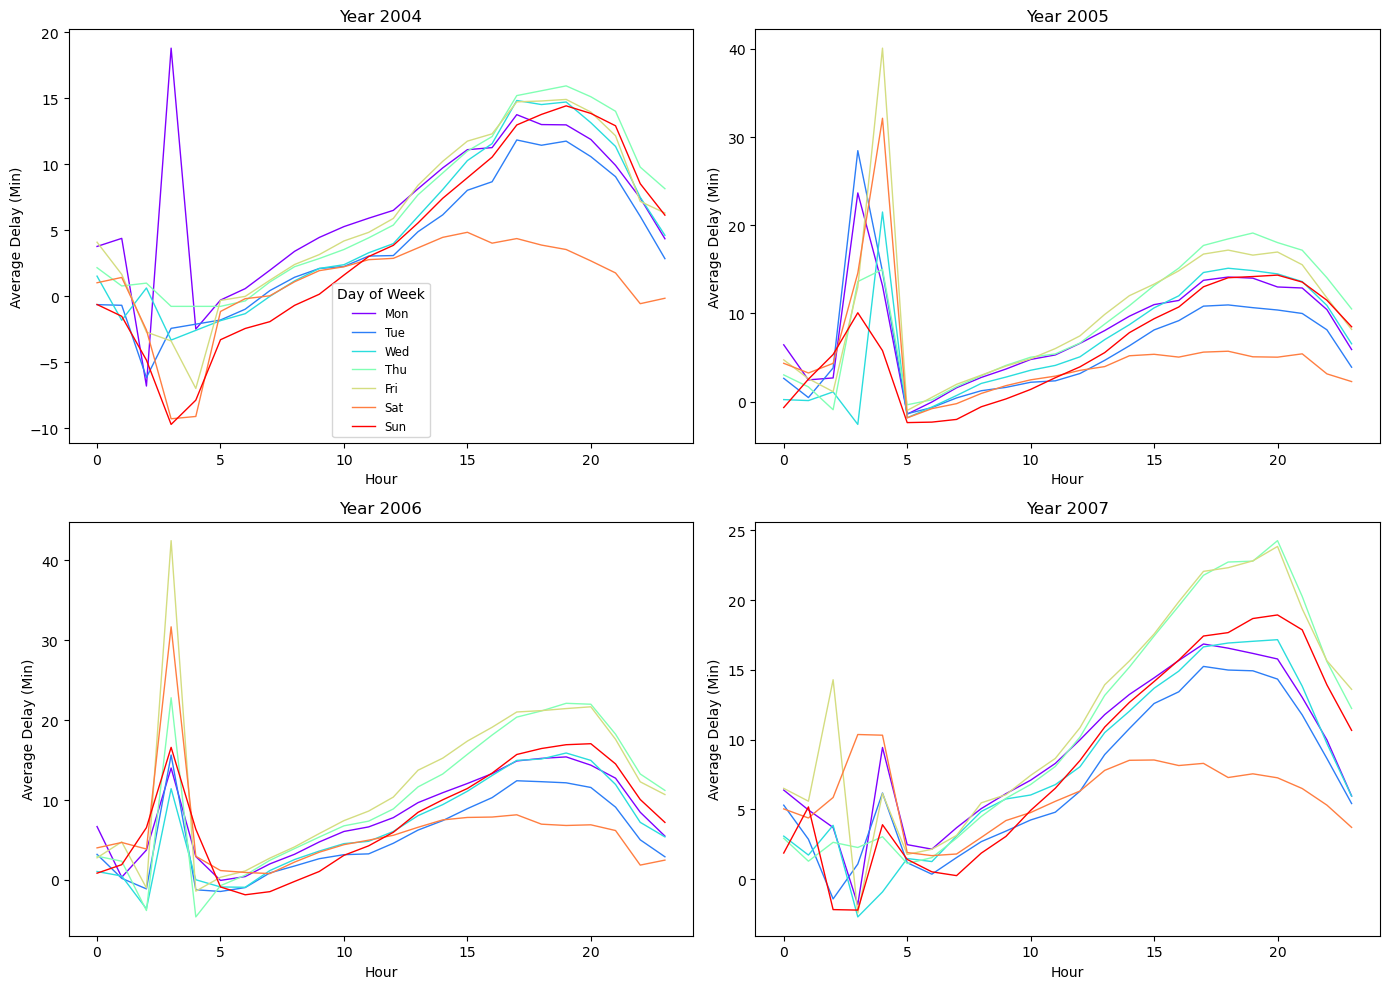

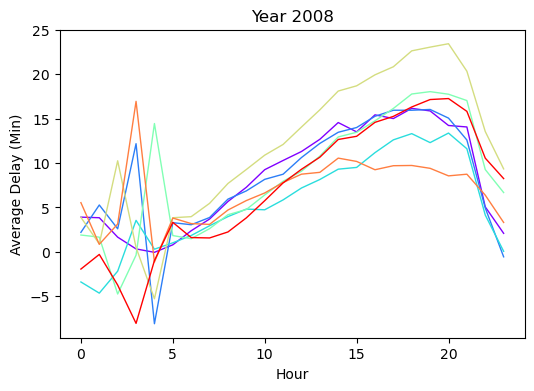

In [100]:
best_times_graph(best_times)

As seen from the graphs below, the best time to fly is early morning around 4am to 10am on any day of the week. More specifically, a Sunday early morning flight around 4am to 6am as it has the least flight delays base as the pink line, representing Sunday, is consistently the lowest curve on the graph across all five years.

### (b) Evaluate whether older planes suffer more delays on a year-to-year basis.
Create a query to show the Year, PlaneAge and MeanDelay from OnTime,
merge with Plane base on TailNumber, 
where there is no missing data in ArrDelay, TailNum,and Year, and the Plane Age is within reasonable age between 0 and 50
then, group the data by Year, and then Plane Age.
Plane Age is the difference between the Year of Issue and the Year of Data)

In [104]:
query_b = """
SELECT 
    O.Year, 
    (O.Year - CAST(P.year AS INTEGER)) AS PlaneAge, 
    AVG(O.ArrDelay) AS MeanDelay 
FROM OnTime O
INNER JOIN Plane P ON O.TailNum = P.tailnum
WHERE O.ArrDelay IS NOT NULL 
  AND O.TailNum IS NOT NULL
  AND P.year IS NOT NULL 
  AND P.year != 'None'
  AND CAST(P.year AS INTEGER) > 1950
  AND (O.Year - CAST(P.year AS INTEGER)) BETWEEN 0 AND 49
GROUP BY O.Year, PlaneAge
"""

plane_suffer = pd.read_sql_query(query_b, conn)

#### Trend in All Year Graph
This shows a scatter plot of the plane age against average delay (minuted) by all the years.

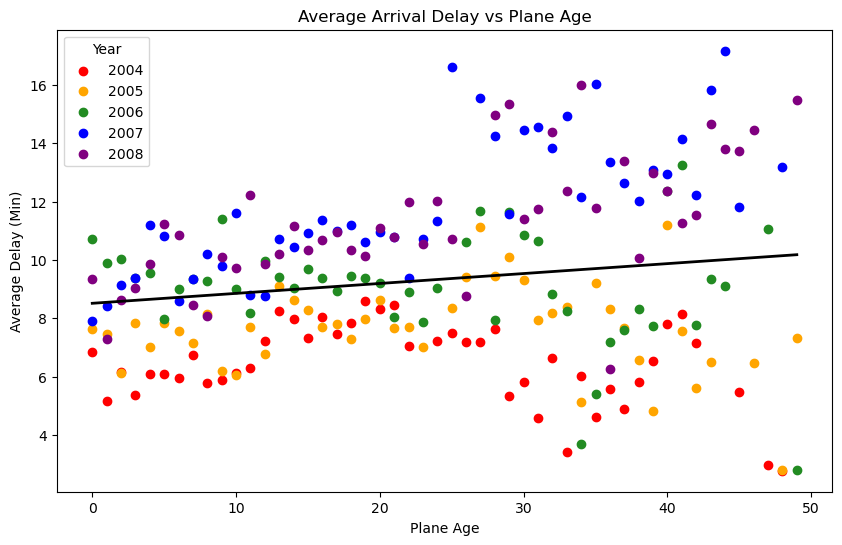

In [134]:
colors = ["red", "orange", "forestgreen", "blue", "purple"]
years_unique = sorted(plane_suffer['Year'].unique())
color_map = dict(zip(years_unique, colors))

plt.figure(figsize=(10, 6))

# Scatterplot
for y in years_unique:
    subset = plane_suffer[plane_suffer['Year'] == y]
    plt.scatter(subset['PlaneAge'], subset['MeanDelay'], color=color_map[y], label=y, zorder=2)

# Trendline (Linear Regression)
m, b = np.polyfit(plane_suffer['PlaneAge'], plane_suffer['MeanDelay'], 1)
plt.plot(plane_suffer['PlaneAge'], m * plane_suffer['PlaneAge'] + b, color="black", linewidth=2, zorder=3)

plt.title("Average Arrival Delay vs Plane Age")
plt.xlabel("Plane Age")
plt.ylabel("Average Delay (Min)")
plt.legend(title="Year")
plt.show()

Base on the scatterplot below, while there is a positive correlation between a plane's age and its average delay, the year the flight took place is much stronger driver of delays than the age of the aircraft. Observing the trend line, there were higher average delays in the year 2008 (purple) and 2007 (blue) as compared to in year 2004 (red) and 2005 (orange) regardless of the age of the plane were ranging between 5 years old to 40 years old.

### (c) Fit a logistic regression model for the probability of diverted US flights.

In [110]:
query_c = """
SELECT 
    O.Year, O.Month, O.DayOfWeek, O.CRSDepTime, O.CRSArrTime, O.Distance, 
    A1.lat AS OriginLat, A1.long AS OriginLong, 
    A2.lat AS DestLat, A2.long AS DestLong, 
    O.Diverted
FROM OnTime O
INNER JOIN Airport A1 ON O.Origin = A1.iata
INNER JOIN Airport A2 ON O.Dest = A2.iata
WHERE O.Diverted IS NOT NULL
"""

flight_features = pd.read_sql_query(query_c, conn)

# Take 30% random sample grouped by year
features = flight_features.groupby("Year").sample(frac=0.3, random_state=42).reset_index(drop=True)

#### Logistic Regression
Subset data for the year.
Then, fit the model into a logistic regression.
Afterwards, extract the coefficients without the intercept and combine results into a dataframe for plotting.

In [117]:
years_model = features['Year'].unique()
model_results = []

for y in years_model:
    year_data = features[features['Year'] == y]
    
    # Formula
    formula = "Diverted ~ Month + DayOfWeek + CRSDepTime + CRSArrTime + Distance + OriginLat + OriginLong + DestLat + DestLong"
    
    # Fit Logistic Regression Model
    model = smf.logit(formula=formula, data=year_data).fit(disp=0)
    
    # Extract coefficients
    coeffs = model.params.drop("Intercept", errors="ignore").to_dict()
    coeffs['Year'] = y
    
    model_results.append(coeffs)

# Combine results into DataFrame
coeffs_df = pd.DataFrame(model_results)

#### Logistic Regression Graph
The graph shows the estimated coefficients of Distance feature predicting flight diversions from 2004 to 2008. The Distance displays consistency in maintaining positive relationship with diversions across all years. However, its impact is not static. The Distance influence on the model grew steadily to a peak in 2006 before a sharp decline through 2008, where its predictive effect is weakest.

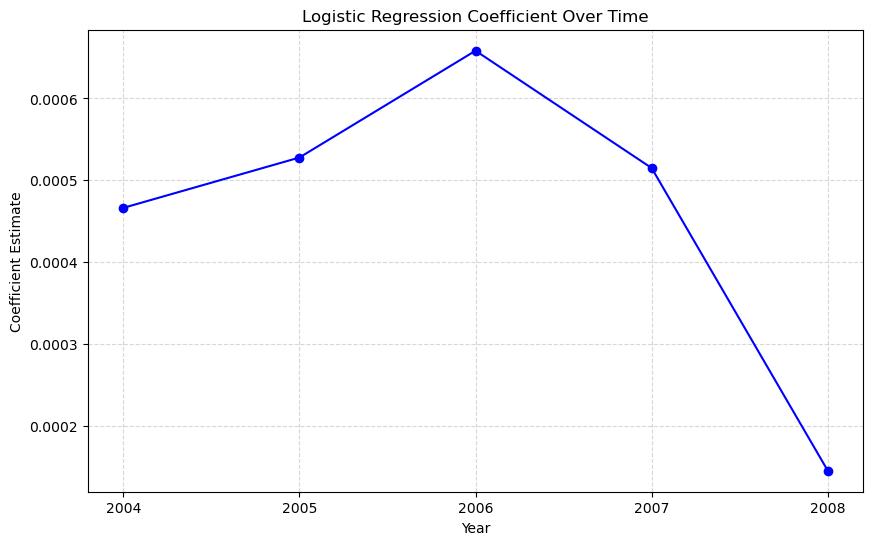

In [119]:
# Sort values by Year to ensure the line plot connects correctly
coeffs_df = coeffs_df.sort_values(by="Year")

plt.figure(figsize=(10, 6))
plt.plot(coeffs_df['Year'], coeffs_df['Distance'], marker='o', linestyle='-', color='blue')

plt.title("Logistic Regression Coefficient Over Time")
plt.xlabel("Year")
plt.ylabel("Coefficient Estimate")
plt.xticks(coeffs_df['Year'])
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Close the database connection at the end of the script

In [137]:
conn.close()